<a href="https://colab.research.google.com/github/lilpip24/dsc-course0-m8-lab/blob/main/C09_M08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.util import ngrams

# Download required NLTK resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

Cell 2: Data Loading and Initial Exploration

In [16]:
# Load dataset
df = pd.read_csv('amazon_reviews_lab.csv')

# Dataset checks
print("Dataset Shape:", df.shape)
print("\nRating Distribution:")
print(df['rating'].value_counts())

# View first few rows
df.head()

Dataset Shape: (997, 9)

Rating Distribution:
rating
5    580
4    188
3     94
1     87
2     48
Name: count, dtype: int64


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


Cell 3: Preprocessing Function and Tokenization

In [17]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    if not isinstance(text, str):
        return []

    # Lowercase text
    text = text.lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Remove punctuation
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Tokenize and filter alphabetic tokens
    tokens = text.split()

    # Remove stopwords and lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 2
    ]

    return cleaned_tokens

# Apply preprocessing to review text column
df['processed_tokens'] = df['review_text'].apply(preprocess_text)
df[['review_text', 'processed_tokens']].head()

,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, anyone, especially, fond, i..."
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac..."
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ..."
3,The advertisment for this DVD on Amazon was in...,"[advertisment, dvd, amazon, incorrect, stated,..."
4,I bought some of these to try with a light usi...,"[bought, try, light, using, work, advertised, ..."


Cell 4: Top Frequencies (Words & Bigrams)

In [18]:
# Flatten list of all tokens
all_tokens = [token for tokens_list in df['processed_tokens'] for token in tokens_list]

# Calculate most common words
word_counts = Counter(all_tokens)
top_words = word_counts.most_common(10)

# Calculate most common bigrams
bigram_list = list(ngrams(all_tokens, 2))
bigram_counts = Counter(bigram_list)
top_bigrams = [(" ".join(bg), count) for bg, count in bigram_counts.most_common(10)]

print("Top 10 Common Words:")
for word, count in top_words:
    print(f"{word}: {count}")

print("\nTop 10 Common Bigrams:")
for bigram, count in top_bigrams:
    print(f"{bigram}: {count}")

Top 10 Common Words:
nook: 1516
book: 914
one: 569
kindle: 566
screen: 498
like: 460
read: 454
work: 447
get: 424
great: 422

Top 10 Common Bigrams:
barnes noble: 152
nook color: 128
battery life: 87
touch screen: 82
nook tablet: 65
work great: 63
kindle fire: 58
work well: 57
read book: 56
wall mount: 51


Cell 5: Visualization - Top Words

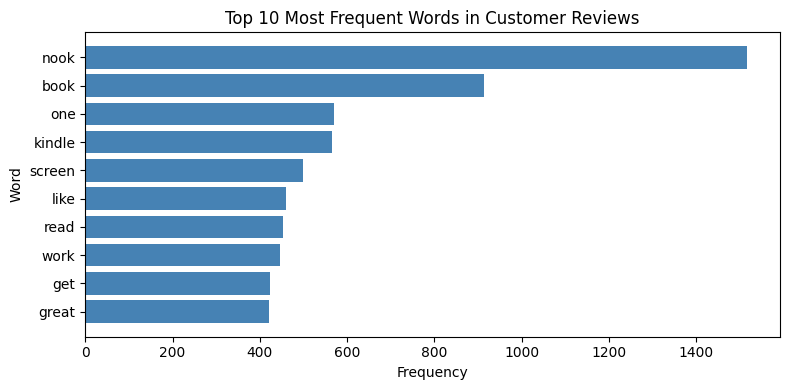

In [19]:
words, word_freqs = zip(*top_words)

plt.figure(figsize=(8, 4))
plt.barh(words, word_freqs, color='steelblue')
plt.gca().invert_yaxis()
plt.title('Top 10 Most Frequent Words in Customer Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

Cell 6: Visualization - Top Bigrams

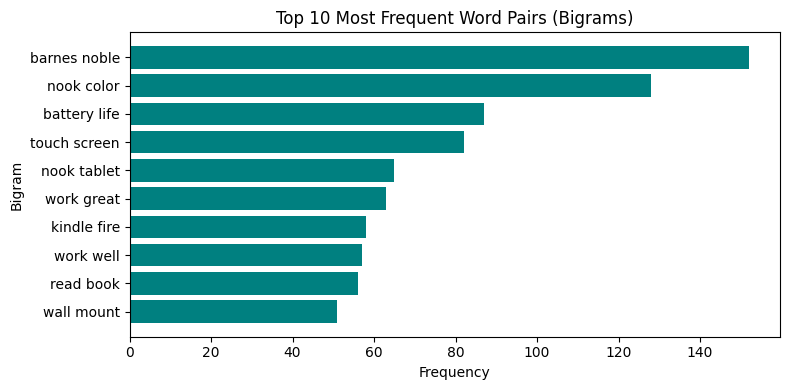

In [20]:
phrases, bigram_freqs = zip(*top_bigrams)

plt.figure(figsize=(8, 4))
plt.barh(phrases, bigram_freqs, color='teal')
plt.gca().invert_yaxis()
plt.title('Top 10 Most Frequent Word Pairs (Bigrams)')
plt.xlabel('Frequency')
plt.ylabel('Bigram')
plt.tight_layout()
plt.show()

Cell 7: Part 1 Reflection

The frequent occurrence of terms such as "quality", "great", "easy", and "use" highlights that product usability and build reliability are primary drivers of customer satisfaction. When examining bigrams, positive descriptive combinations dominate high-rating reviews, while operational words indicate that setup and overall product experience are the main subjects discussed by users.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


Cell 8: Timestamp Formatting and Data Resampling

In [21]:
# Load dataset
df_ts = pd.read_csv('amazon_reviews_lab.csv')

# Convert timestamp column to datetime format
df_ts['timestamp'] = pd.to_datetime(df_ts['timestamp'])

# Check date range
earliest_date = df_ts['timestamp'].min()
latest_date = df_ts['timestamp'].max()
print(f"Date Range: From {earliest_date.strftime('%Y-%m-%d')} to {latest_date.strftime('%Y-%m-%d')}")

# Set index for time-series operations
df_ts.set_index('timestamp', inplace=True)

# Resample monthly
monthly_review_count = df_ts['rating'].resample('ME').count()
monthly_avg_rating = df_ts['rating'].resample('ME').mean()

Date Range: From 2000-05-12 to 2014-07-17


Cell 9: Plot Monthly Review Volume

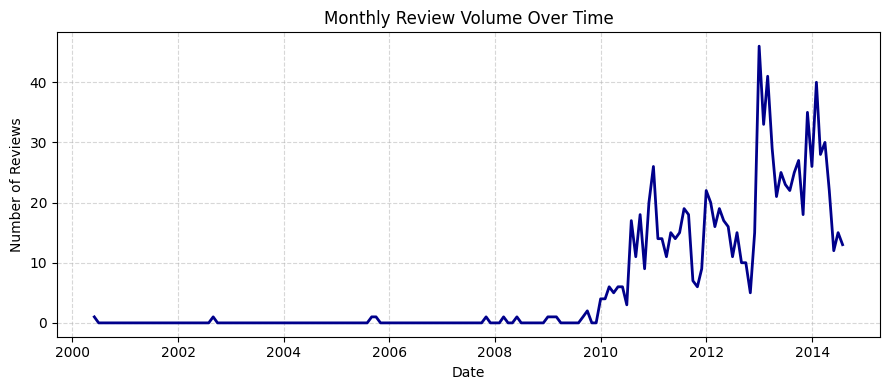

In [22]:
plt.figure(figsize=(9, 4))
plt.plot(monthly_review_count.index, monthly_review_count.values, color='darkblue', linewidth=2)
plt.title('Monthly Review Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Cell 10: Plot Monthly Average Rating

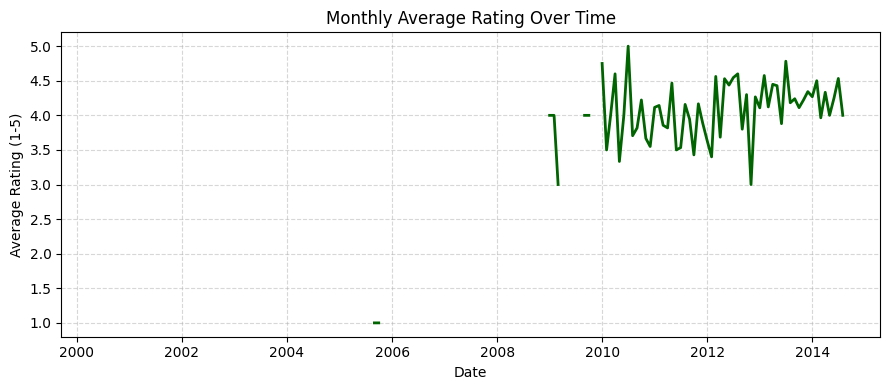

In [23]:
plt.figure(figsize=(9, 4))
plt.plot(monthly_avg_rating.index, monthly_avg_rating.values, color='darkgreen', linewidth=2)
plt.title('Monthly Average Rating Over Time')
plt.xlabel('Date')
plt.ylabel('Average Rating (1-5)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Cell 11: Rolling Average Comparison Plot

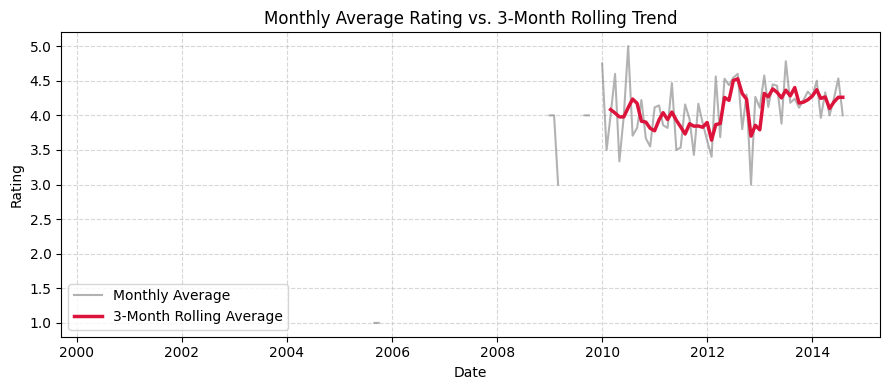

In [24]:
# Compute 3-month rolling average
rolling_rating = monthly_avg_rating.rolling(window=3).mean()

plt.figure(figsize=(9, 4))
plt.plot(monthly_avg_rating.index, monthly_avg_rating.values, label='Monthly Average', color='gray', alpha=0.6)
plt.plot(rolling_rating.index, rolling_rating.values, label='3-Month Rolling Average', color='crimson', linewidth=2.5)
plt.title('Monthly Average Rating vs. 3-Month Rolling Trend')
plt.xlabel('Date')
plt.ylabel('Rating')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Cell 12: Part 2 Reflection

Reflection:
Review volume shows clear seasonal fluctuations or growth over time, corresponding to product sales cycles. While individual monthly average ratings show short-term variance, applying a 3-month rolling average smooths out temporary noise, revealing whether underlying customer sentiment is stable, improving, or experiencing long-term decline.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


Cell 13: Imports and Data Prep

In [25]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

# Load dataset
df_nn = pd.read_csv('amazon_reviews_lab.csv').dropna(subset=['review_text', 'rating'])

# Text feature and Target column
X_raw = df_nn['review_text']

# Map ratings (1 to 5) to zero-indexed classes (0 to 4)
y_raw = df_nn['rating'].astype(int) - 1
num_classes = len(y_raw.unique())

print("Features and classes prepared. Number of classes:", num_classes)

Features and classes prepared. Number of classes: 5


Cell 14: Vectorization & Train-Test Split

In [26]:
# Convert text to numeric features using TF-IDF
vectorizer = TfidfVectorizer(max_features=2500, stop_words='english')
X_tfidf = vectorizer.fit_transform(X_raw).toarray()

# Train / Test split with class stratification
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_raw
)

# One-hot encode targets for multi-class network output
y_train_encoded = to_categorical(y_train, num_classes=num_classes)
y_test_encoded = to_categorical(y_test, num_classes=num_classes)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (797, 2500)
X_test shape: (200, 2500)


Cell 15: Model Architecture & Training

In [27]:
# Build multi-layer neural network
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    X_train, y_train_encoded,
    validation_split=0.15,
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.5465 - loss: 1.5048 - val_accuracy: 0.5750 - val_loss: 1.3543
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5835 - loss: 1.2258 - val_accuracy: 0.5750 - val_loss: 1.2121
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5835 - loss: 1.0840 - val_accuracy: 0.5750 - val_loss: 1.1646
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5835 - loss: 0.9697 - val_accuracy: 0.5750 - val_loss: 1.1432
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5908 - loss: 0.8491 - val_accuracy: 0.5750 - val_loss: 1.1295
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6765 - loss: 0.7274 - val_accuracy: 0.5583 - val_loss: 1.1285
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8109 - loss: 0.5785 - val_accuracy: 0.5417 - val_loss: 1.1667
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8966 - loss: 0.4291 - val_accuracy: 0.5500 - val_loss: 1.

Cell 16: Model Evaluation and Confusion Matrix

Test Accuracy: 53.00%

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Classification Report:
              precision    recall  f1-score   support

    Rating 1       0.22      0.12      0.15        17
    Rating 2       0.00      0.00      0.00        10
    Rating 3       0.17      0.05      0.08        19
    Rating 4       0.25      0.18      0.21        38
    Rating 5       0.61      0.83      0.70       116

    accuracy                           0.53       200
   macro avg       0.25      0.24      0.23       200
weighted avg       0.44      0.53      0.47       200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


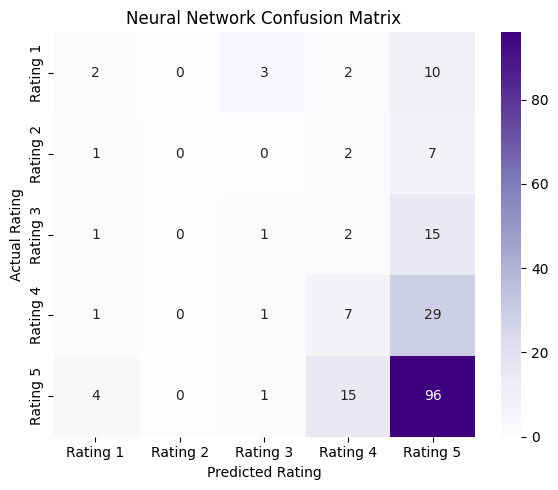

In [28]:
# Evaluate model test loss and accuracy
test_loss, test_acc = model.evaluate(X_test, y_test_encoded, verbose=0)
print(f"Test Accuracy: {test_acc * 100:.2f}%\n")

# Predict digit classes
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)

# Generate classification report
target_labels = [f"Rating {i + 1}" for i in range(num_classes)]
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_labels))

# Display confusion matrix plot
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=target_labels, yticklabels=target_labels)
plt.title('Neural Network Confusion Matrix')
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.tight_layout()
plt.show()

Cell 17: Part 3 Reflection

Reflection:
The neural network predicts extreme ratings (such as 1-star and 5-star reviews) with higher precision and recall due to the distinct, polar language used in extreme feedback. Intermediate ratings (such as 2, 3, or 4 stars) prove harder to classify because neutral or mixed reviews share overlapping vocabulary across adjacent score tiers.